## Project Title: House Price Prediction
BY: Nana Yaw A.


## Description:
In this project, we aim to develop a machine learning model that predicts the prices of houses based on various features such as location, size, number of bedrooms, number of bathrooms, amenities, and other relevant factors. We will use a dataset containing historical housing data, including features and corresponding sale prices, to train and evaluate the model.

## Dataset Description
This dataset provides comprehensive information for house price prediction, with 13 column names:

- Price: The price of the house.
- Area: The total area of the house in square feet.
- Bedrooms: The number of bedrooms in the house.
- Bathrooms: The number of bathrooms in the house.
- Stories: The number of stories in the house.
- Mainroad: Whether the house is connected to the main road (Yes/No).
- Guestroom: Whether the house has a guest room (Yes/No).
- Basement: Whether the house has a basement (Yes/No).
- Hot water heating: Whether the house has a hot water heating system (Yes/No).
- Airconditioning: Whether the house has an air conditioning system (Yes/No).
- Parking: The number of parking spaces available within the house.
- Prefarea: Whether the house is located in a preferred area (Yes/No).
- Furnishing status: The furnishing status of the house (Fully Furnished, Semi-Furnished, Unfurnished).

## Goal 
Analyze the data provided and build a linear regression model to predict the price of a house and identify factors that significantly influence it.

### Importing needed libraries and modules
Please make sure you've installed all the required libraries and modules

In [49]:
import numpy as np
import pandas as pd

#For visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

#For vectorizing and splitting data
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split

#For training
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

#For model Evaluation
from sklearn.metrics import root_mean_squared_error, r2_score, mean_squared_error

import warnings
warnings.filterwarnings('ignore')

### Loading and creating a copy

In [50]:
housing_main = pd.read_csv("Housing.csv")

housing = housing_main.copy()

### Setting an index column as id

In [51]:
#Creating an a new column to store the indexes
housing.insert(0,'id',range(len(housing))) # The insert function takes the index of the column, name and content of the column
housing.index = housing['id']

### EDA

In [52]:
#checking colums and dtypes
housing.info()

<class 'pandas.core.frame.DataFrame'>
Index: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id                545 non-null    int64 
 1   price             545 non-null    int64 
 2   area              545 non-null    int64 
 3   bedrooms          545 non-null    int64 
 4   bathrooms         545 non-null    int64 
 5   stories           545 non-null    int64 
 6   mainroad          545 non-null    object
 7   guestroom         545 non-null    object
 8   basement          545 non-null    object
 9   hotwaterheating   545 non-null    object
 10  airconditioning   545 non-null    object
 11  parking           545 non-null    int64 
 12  prefarea          545 non-null    object
 13  furnishingstatus  545 non-null    object
dtypes: int64(7), object(7)
memory usage: 63.9+ KB


In [53]:
#viewing top 10 to confirm dtypes
housing.head(10)

,id,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
id,,,,,,,,,,,,,,
0,0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished


In [54]:
#viewing bottom 5
housing.tail()

,id,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
id,,,,,,,,,,,,,,
540,540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished
544,544,1750000,3850,3,1,2,yes,no,no,no,no,0,no,unfurnished


In [55]:
housing.describe().round()

,id,price,area,bedrooms,bathrooms,stories,parking
count,545.0,545.0,545.0,545.0,545.0,545.0,545.0
mean,272.0,4766729.0,5151.0,3.0,1.0,2.0,1.0
std,157.0,1870440.0,2170.0,1.0,1.0,1.0,1.0
min,0.0,1750000.0,1650.0,1.0,1.0,1.0,0.0
25%,136.0,3430000.0,3600.0,2.0,1.0,1.0,0.0
50%,272.0,4340000.0,4600.0,3.0,1.0,2.0,0.0
75%,408.0,5740000.0,6360.0,3.0,2.0,2.0,1.0
max,544.0,13300000.0,16200.0,6.0,4.0,4.0,3.0


<Axes: xlabel='price', ylabel='Count'>

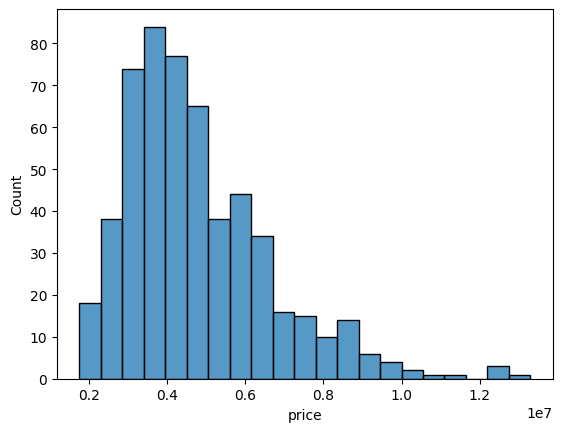

In [56]:
#checking for price distibution

sns.histplot(housing.price.round())

In [57]:
housing.price

id
0      13300000
1      12250000
2      12250000
3      12215000
4      11410000
         ...   
540     1820000
541     1767150
542     1750000
543     1750000
544     1750000
Name: price, Length: 545, dtype: int64

<Axes: xlabel='price'>

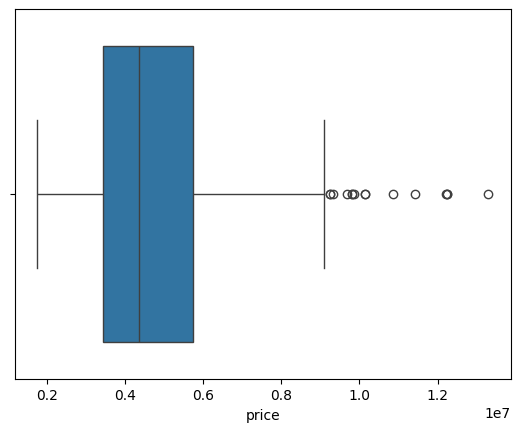

In [58]:
#Checking for outliers
sns.boxplot(data=housing, x='price')

In [59]:
#Checking the correlation between the independent variables and price
housing.select_dtypes(exclude='O').corr().price #it is the normal correlation table we do just that this time round i only pick the price column with '.price'

id          -0.929878
price        1.000000
area         0.535997
bedrooms     0.366494
bathrooms    0.517545
stories      0.420712
parking      0.384394
Name: price, dtype: float64

<Axes: >

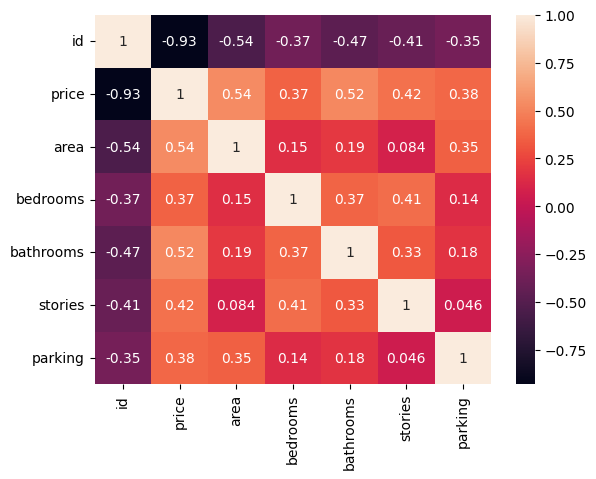

In [60]:
#A heatmap of the correlation between numerical variables
sns.heatmap(housing.select_dtypes(exclude='O').corr(), annot=True)

In [61]:
#setting the features
features_data = housing[['area','bedrooms','bathrooms','stories','mainroad','guestroom','basement','hotwaterheating','airconditioning','parking','prefarea','furnishingstatus']]


In [62]:
# changing each observationl in the features table to dictionary
features_dict = features_data.to_dict(orient='records')

In [63]:
dv = DictVectorizer()
dv.fit(features_dict)

DictVectorizer()

## Splitting Dataset
- Training set 80%
- Test dataset 20%

In [64]:
#transforming the features_dict and storing it as features for the training
#storing the label data as 'label' for training
features = dv.transform(features_dict)
label = np.log1p(housing.price).values

In [65]:
#Splittin the data into 'x_train' and 'x_test' = features of training and testing data respectively. 'y_trian' and 'y_test' = label or predicted value for the training  and testing data respectively.
#The 'train_test_split' function can take two dataframes and split the firt dataframe('features' in this case) and assign it to the first two variables('x_train' and 'x_test' in this case) in 8:2 ratio respectively. Then it takes the second dataframe('label' in this case) then splits it for the third and fourth variable('y_train' and 'y_test') in 8:2 ratio.
x_train,x_test,y_train,y_test = train_test_split(features,label,test_size=0.2,random_state=8)

## Training with different models
In this section we'll train the data with different models to find the best model. These are the models we're going to train the data with:
- Decision Tree Regressor 
- Gradient Boosting Regressor
- Support Vector Regressor
- XGboost Regressor
- Linear Regression
- Random Forest Regressor

For each of these models I will follow the same steps so i won't comment
1. Import the model and give it a variable name
2. Fit(train) the model('model.fit()') with the training('x_train') and the testing('y_train') data
3. Predict the labels for the testing data('model.predict(x_test)')
4. Calculate the root_mean_squared_error with the actual labe('y_test') and the predicted labels from 'model.predict(x_test)'
5. Similarly calculate the R2_Score for each model
6. Then calculate the mean squared error for each model

### Using Decision Tree Regressor

In [66]:
dtr_model = DecisionTreeRegressor()
dtr_model.fit(x_train,y_train)

DecisionTreeRegressor()

In [67]:
dtr_test_pred= dtr_model.predict(x_test)


In [68]:
dtr_rmse = root_mean_squared_error(y_test,dtr_test_pred)
print(f"The Root mean squared error = {dtr_rmse.round(3)}")


The Root mean squared error = 0.309


In [69]:
dtr_r2_score =r2_score(y_test,dtr_test_pred)
print(f"The R2 Score = {dtr_r2_score}")

The R2 Score = 0.3165148245835355


In [70]:
dtr_mse = mean_squared_error(y_test,dtr_test_pred)
print(f"The mean squared error = {dtr_mse}")

The mean squared error = 0.09527464261867989


### Using Gradient Boosting Regressor

In [71]:
gboost_model = GradientBoostingRegressor(learning_rate = .07,n_estimators = 500, verbose=0)
gboost_model.fit(x_train,y_train)

GradientBoostingRegressor(learning_rate=0.07, n_estimators=500)

In [72]:
gboost_test_pred= gboost_model.predict(x_test)

In [73]:
gboost_rmse = root_mean_squared_error(y_test,gboost_test_pred)
print(f"The Root mean squared error = {gboost_rmse.round(3)}")

The Root mean squared error = 0.203


In [74]:
gboost_r2_score =r2_score(y_test,gboost_test_pred)
print(f"The R2 Score = {gboost_r2_score}")

The R2 Score = 0.7035786200212688


In [75]:
gboost_mse = mean_squared_error(y_test,gboost_test_pred)
print(f"The mean squared error = {gboost_mse}")

The mean squared error = 0.04131975653283383


### Using Support Vector Regressor

In [76]:
svc_model = SVR()
svc_model.fit(x_train,y_train)

SVR()

In [77]:
svc_test_pred= svc_model.predict(x_test)

In [78]:
svc_rmse = root_mean_squared_error(y_test,svc_test_pred)
print(f"The Root mean squared error = {svc_rmse.round(3)}")

The Root mean squared error = 0.277


In [79]:
svc_r2_score =r2_score(y_test,svc_test_pred)
print(f"The R2 Score = {svc_r2_score}")

The R2 Score = 0.449851046469656


In [80]:
svc_mse = mean_squared_error(y_test,svc_test_pred)
print(f"The mean squared error = {svc_mse}")

The mean squared error = 0.07668819576475282


### Using XGBoost Regressor

In [81]:
xgb_model = XGBRegressor(ax_depth= 7,n_estimators=500,learnin_rate=0.05)
xgb_model.fit(x_train,y_train)

XGBRegressor(ax_depth=7, base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learnin_rate=0.05,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, ...)

In [82]:
xgb_test_pred= xgb_model.predict(x_test)

In [83]:
xgb_rmse = root_mean_squared_error(y_test,xgb_test_pred)
print(f"The Root mean squared error = {xgb_rmse.round(3)}")

The Root mean squared error = 0.214


In [84]:
xgb_r2_score =r2_score(y_test,xgb_test_pred)
print(f"The R2 Score = {xgb_r2_score}")


The R2 Score = 0.6708518712692132


In [85]:
xgb_mse = mean_squared_error(y_test,xgb_test_pred)
print(f"The mean squared error = {xgb_mse}")

The mean squared error = 0.045881712524817896


### Using Linear Regression 

In [86]:
lr_model = LinearRegression()
lr_model.fit(x_train,y_train)


LinearRegression()

In [87]:
lr_test_pred= lr_model.predict(x_test)

In [88]:
lr_rmse = root_mean_squared_error(y_test,lr_test_pred)
print(f" The root mean squared error ={lr_rmse}")

 The root mean squared error =0.18583299176331816


In [89]:
lr_r2_score =r2_score(y_test,lr_test_pred)
print(f"The R2 Score = {lr_r2_score}")

The R2 Score = 0.7522592726009208


In [90]:
lr_mse = mean_squared_error(y_test,lr_test_pred)
print(f"The mean squared error = {lr_mse}")

The mean squared error = 0.03453390082770547


### Using Random Forest Regressor

In [91]:
rf_model = RandomForestRegressor(n_estimators=1000,random_state=65)
rf_model.fit(x_train,y_train)

RandomForestRegressor(n_estimators=1000, random_state=65)

In [92]:
rf_test_pred = rf_model.predict(x_test)

In [93]:
rf_rmse = root_mean_squared_error(y_test,rf_test_pred)
print(f"The Root mean squared error = {rf_rmse}")


The Root mean squared error = 0.20098640435565004


In [94]:
rf_r2_score = r2_score(y_test,rf_test_pred)
print(f"The R2 Score = {rf_r2_score}")

The R2 Score = 0.7102088406098552


In [95]:
rf_mse = mean_squared_error(y_test,rf_test_pred)
print(f"The mean squared error = {rf_mse}")

The mean squared error = 0.040395534735812866


### Summary
This is a summary of the R2_Score, the root mean squred error and the mean squared error of each of the models

In [96]:
print(f"\033[1m For XGBRegressor \033[0m \n The R2 Score = {xgb_r2_score}\n The Root mean squared error = {xgb_rmse.round(3)}\n The mean squred error = {xgb_mse} \n")

print(f"\033[1m For LinearRegression \033[0m \n The R2 Score = {lr_r2_score}\n The Root mean squared error = {lr_rmse.round(3)}\n The mean squred error = {lr_mse} \n")

print(f"\033[1m For RandomForestRegressor \033[0m\n The R2 Score = {rf_r2_score}\n The Root mean squared error = {rf_rmse.round(3)}\n The mean squred error = {rf_mse}\n")

print(f"\033[1m For Support Vector Regression \033[0m\n The R2 Score = {svc_r2_score}\n The Root mean squared error = {svc_rmse.round(3)}\n The mean squred error = {svc_mse}\n")

print(f"\033[1m For Gradient Boosting Regressor \033[0m\n The R2 Score = {gboost_r2_score}\n The Root mean squared error = {gboost_rmse.round(3)}\n The mean squred error = {gboost_mse}\n")

print(f"\033[1m For Decision Tree Regressor \033[0m\n The R2 Score = {dtr_r2_score}\n The Root mean squared error = {dtr_rmse.round(3)}\n The mean squred error = {dtr_mse}\n")



 For XGBRegressor  
 The R2 Score = 0.6708518712692132
 The Root mean squared error = 0.214
 The mean squred error = 0.045881712524817896 

 For LinearRegression  
 The R2 Score = 0.7522592726009208
 The Root mean squared error = 0.186
 The mean squred error = 0.03453390082770547 

 For RandomForestRegressor 
 The R2 Score = 0.7102088406098552
 The Root mean squared error = 0.201
 The mean squred error = 0.040395534735812866

 For Support Vector Regression 
 The R2 Score = 0.449851046469656
 The Root mean squared error = 0.277
 The mean squred error = 0.07668819576475282

 For Gradient Boosting Regressor 
 The R2 Score = 0.7035786200212688
 The Root mean squared error = 0.203
 The mean squred error = 0.04131975653283383

 For Decision Tree Regressor 
 The R2 Score = 0.3165148245835355
 The Root mean squared error = 0.309
 The mean squred error = 0.09527464261867989



- From the evaluation summary liner Regression has the best R2 score and hence will be used as the model

### Saving  model

In [97]:
import pickle

with open('House Price Pridiction.pkl', 'wb') as md:
    pickle.dump((dv,lr_model), md)